In [1]:
%pip install pandas numpy matplotlib plotly statsbombpy mplsoccer

  Using cached numpy-2.5.4-cp313-cp313-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached charset_normalizer-3.5.2-cp313-cp313-macosx_10_13_universal2.whl.metadata (46 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 18.1 MB/s  0:00:00eta 0:00:01
Using cached numpy-2.5.4-cp313-cp313-macosx_14_0_arm64.whl (5.4 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 19.8 MB/s  0:00:00 eta 0:00:01
Using c

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import plotly.express as px
import plotly.graph_objects as go

from statsbombpy import sb
from mplsoccer import Pitch

import warnings
warnings.filterwarnings("ignore")

# Mapping Messi: Visualizing When, Where, and How Lionel Messi Scores

## Team Members
- Essey Beraki
- Luis Chavez
- Sam Banstola

## Project Goal

This project analyzes Lionel Messi's scoring patterns using temporal,
categorical, and spatial visualizations.

We investigate two primary case studies:

### Case Study 1: The Anatomy of a Messi Goal
How do finishing method, playing position, match timing, assists,
and shot location define Lionel Messi's scoring style?

### Case Study 2: The Evolution of Messi's Career
How did Messi's scoring change across seasons, competitions,
opponents, and match environments?


## Data Sources

### Dataset 1: Lionel Messi Club Career Goals
https://github.com/ashgithub0208/Lionel_Messi_Club_Career_Analysis

This dataset contains 704 Lionel Messi club goals with attributes including:

- Season
- Competition
- Matchday
- Date
- Venue
- Club
- Opponent
- Result
- Playing Position
- Minute
- Goal Type
- Assist

### Dataset 2: StatsBomb Open Data
https://github.com/hudl/open-data

StatsBomb event data is used for detailed spatial analysis such as
shot locations, expected goals, body part, and shot outcome.

In [6]:
df = pd.read_csv("data/messi_goals.csv")

print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

Rows: 704
Columns: 13


,Season,Competition,Matchday,Date,Venue,Club,Opponent,Result,Playing_Position,Minute,At_score,Type,Goal_assist
0,04/05,LaLiga,34,05-01/05,H,FC Barcelona,Albacete Balompie,2:00,CF,90+1,2:00,Left-footed shot,Ronaldinho Gaacho
1,05/06,UEFA Champions League,Group Stage,11-02/05,H,FC Barcelona,Panathinaikos Athens,5:00,RW,34,3:00,Left-footed shot,NaN
2,05/06,LaLiga,13,11/27/05,H,FC Barcelona,Racing Santander,4:01,RW,51,2:00,Left-footed shot,Samuel Etoo
3,05/06,LaLiga,19,1/15/06,H,FC Barcelona,Athletic Bilbao,2:01,RW,50,2:01,Left-footed shot,Mark van Bommel
4,05/06,LaLiga,20,1/22/06,H,FC Barcelona,Deportivo Alaves,2:00,CF,82,2:00,Left-footed shot,Ronaldinho Gaacho


In [7]:
messi = df.copy()


In [8]:
text_columns = [
    "Season",
    "Competition",
    "Venue",
    "Club",
    "Opponent",
    "Playing_Position",
    "Type",
    "Goal_assist"
]

for col in text_columns:
    if col in messi.columns:
        messi[col] = messi[col].astype(str).str.strip()

In [9]:
messi = messi.replace("nan", np.nan)

In [10]:
position_map = {
    "RW": "Right Winger",
    "CF": "Centre Forward",
    "LW": "Left Winger",
    "SS": "Second Striker",
    "AM": "Attacking Midfielder"
}

messi["Position_Clean"] = messi["Playing_Position"].replace(position_map)

In [11]:
competition_map = {
    "Champions League": "UEFA Champions League",
    "La Liga": "LaLiga"
}

messi["Competition_Clean"] = messi["Competition"].replace(competition_map)

In [12]:
def clean_goal_type(goal_type):

    if pd.isna(goal_type):
        return "Other"

    goal_type = str(goal_type).lower()

    if "left" in goal_type:
        return "Left Foot"

    elif "right" in goal_type:
        return "Right Foot"

    elif "header" in goal_type:
        return "Header"

    elif "penalty" in goal_type:
        return "Penalty"

    elif "free" in goal_type:
        return "Free Kick"

    elif "solo" in goal_type:
        return "Solo Run"

    else:
        return "Other"


messi["Goal_Type_Clean"] = messi["Type"].apply(clean_goal_type)

In [13]:
def clean_minute(value):

    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    try:

        if "+" in value:
            base, extra = value.split("+")
            return int(base) + int(extra)

        return int(float(value))

    except:
        return np.nan


messi["Minute_Num"] = messi["Minute"].apply(clean_minute)

In [21]:
def minute_period(minute):

    if pd.isna(minute):
        return "Unknown"

    elif minute <= 15:
        return "0-15"

    elif minute <= 30:
        return "16-30"

    elif minute <= 45:
        return "31-45+"

    elif minute <= 60:
        return "46-60"

    elif minute <= 75:
        return "61-75"

    else:
        return "76-90+"


messi["Minute_Period"] = messi["Minute_Num"].apply(minute_period)

period_order = [
    "0-15",
    "16-30",
    "31-45+",
    "46-60",
    "61-75",
    "76-90+"
]

# Case Study 1: The Anatomy of a Messi Goal

## Research Question

How do finishing method, playing position, match timing, assisting
players, and shot location define Lionel Messi's scoring style?

This case study progresses from general scoring characteristics
toward more detailed spatial analysis.

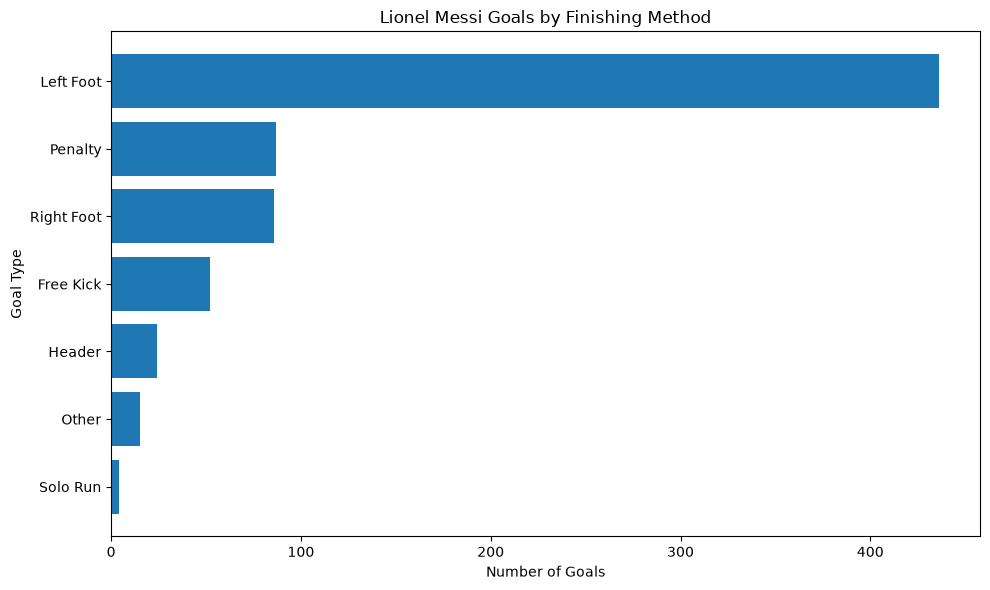

In [15]:
goal_types = messi["Goal_Type_Clean"].value_counts().sort_values()

plt.figure(figsize=(10,6))

plt.barh(
    goal_types.index,
    goal_types.values
)

plt.title("Lionel Messi Goals by Finishing Method")
plt.xlabel("Number of Goals")
plt.ylabel("Goal Type")

plt.tight_layout()
plt.show()

### Interpretation

The chart identifies Messi's most common scoring methods.
Left-footed finishes dominate the distribution, demonstrating how
central his preferred foot has been to his scoring profile.

In [16]:
position_goal = pd.crosstab(
    messi["Position_Clean"],
    messi["Goal_Type_Clean"]
)

position_goal

Goal_Type_Clean,Free Kick,Header,Left Foot,Other,Penalty,Right Foot,Solo Run
Position_Clean,,,,,,,
Attacking Midfielder,1,0,8,0,3,4,0
Centre Forward,16,11,201,4,40,42,2
Left Winger,0,0,1,0,0,0,0
Right Winger,28,12,188,9,40,37,2
Second Striker,7,1,38,2,4,3,0


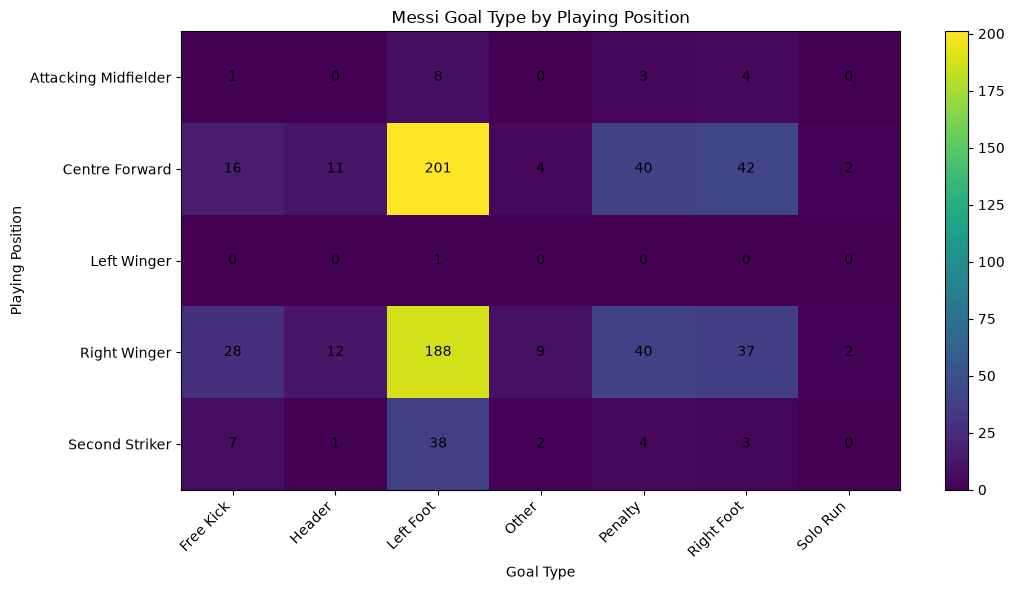

In [17]:
fig, ax = plt.subplots(figsize=(11,6))

image = ax.imshow(position_goal.values, aspect="auto")

ax.set_xticks(range(len(position_goal.columns)))
ax.set_xticklabels(position_goal.columns, rotation=45, ha="right")

ax.set_yticks(range(len(position_goal.index)))
ax.set_yticklabels(position_goal.index)

for i in range(position_goal.shape[0]):
    for j in range(position_goal.shape[1]):

        ax.text(
            j,
            i,
            position_goal.iloc[i, j],
            ha="center",
            va="center"
        )

plt.colorbar(image)

plt.title("Messi Goal Type by Playing Position")
plt.xlabel("Goal Type")
plt.ylabel("Playing Position")

plt.tight_layout()
plt.show()

### Interpretation

This visualization examines whether Messi's scoring methods change
depending on his position. It allows us to compare finishing styles
when playing centrally versus playing as a winger.

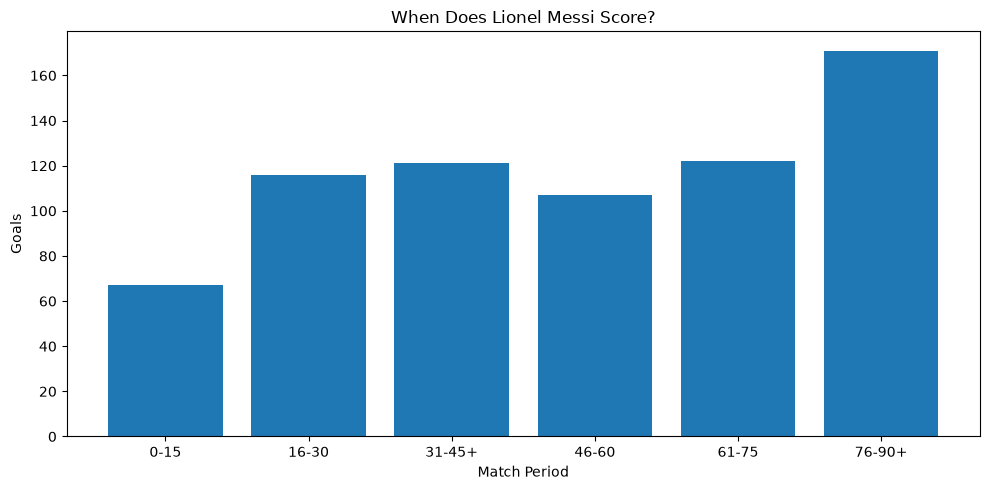

In [23]:
period_counts = (
    messi["Minute_Period"]
    .value_counts()
    .reindex(period_order)
)

plt.figure(figsize=(10,5))

plt.bar(
    period_counts.index,
    period_counts.values
)

plt.title("When Does Lionel Messi Score?")
plt.xlabel("Match Period")
plt.ylabel("Goals")

plt.tight_layout()
plt.show()

In [24]:
assist_data = messi[
    messi["Goal_assist"].notna()
].copy()

top_assists = (
    assist_data["Goal_assist"]
    .value_counts()
    .head(10)
    .sort_values()
)



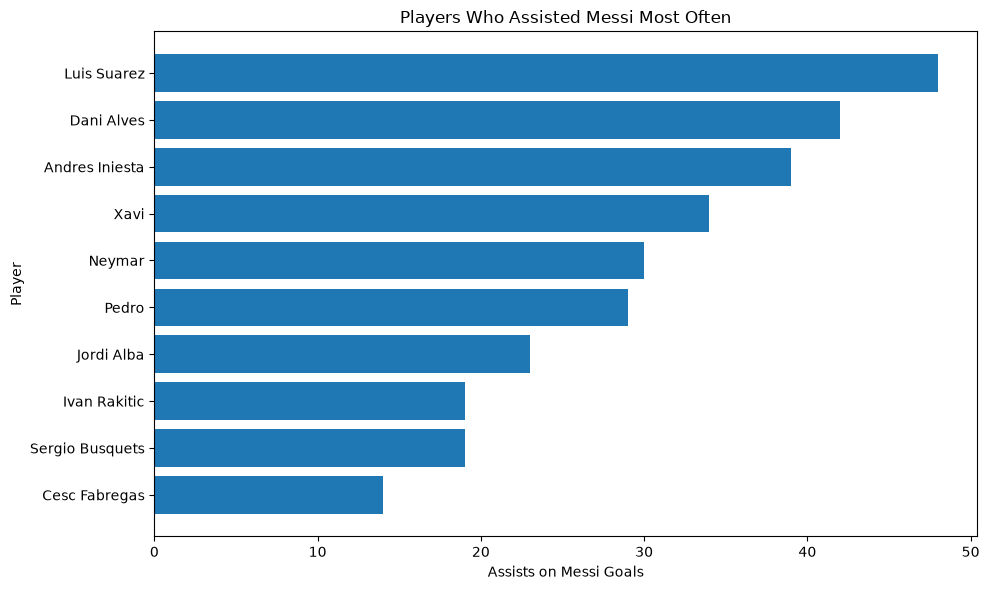

In [25]:
plt.figure(figsize=(10,6))

plt.barh(
    top_assists.index,
    top_assists.values
)

plt.title("Players Who Assisted Messi Most Often")
plt.xlabel("Assists on Messi Goals")
plt.ylabel("Player")

plt.tight_layout()
plt.show()


In [26]:
matches = sb.matches(
    competition_id=11,
    season_id=90
)

matches.head()

barca_matches = matches[
    (matches["home_team"] == "Barcelona") |
    (matches["away_team"] == "Barcelona")
]

print("Barcelona matches:", len(barca_matches))

messi_statsbomb_goals = []

for match_id in barca_matches["match_id"]:

    try:

        events = sb.events(match_id=match_id)

        goals = events[
            (events["player"].astype(str).str.contains(
                "Messi",
                case=False,
                na=False
            ))
            &
            (events["type"] == "Shot")
            &
            (events["shot_outcome"] == "Goal")
        ].copy()

        if len(goals) > 0:

            goals["match_id"] = match_id

            messi_statsbomb_goals.append(goals)

    except Exception as e:
        pass

    

Barcelona matches: 35


In [27]:
if len(messi_statsbomb_goals) > 0:

    sb_goals = pd.concat(
        messi_statsbomb_goals,
        ignore_index=True
    )

else:

    sb_goals = pd.DataFrame()

In [28]:
sb_goals = sb_goals[
    sb_goals["location"].notna()
].copy()

sb_goals["x"] = sb_goals["location"].apply(
    lambda x: x[0]
)

sb_goals["y"] = sb_goals["location"].apply(
    lambda x: x[1]
)

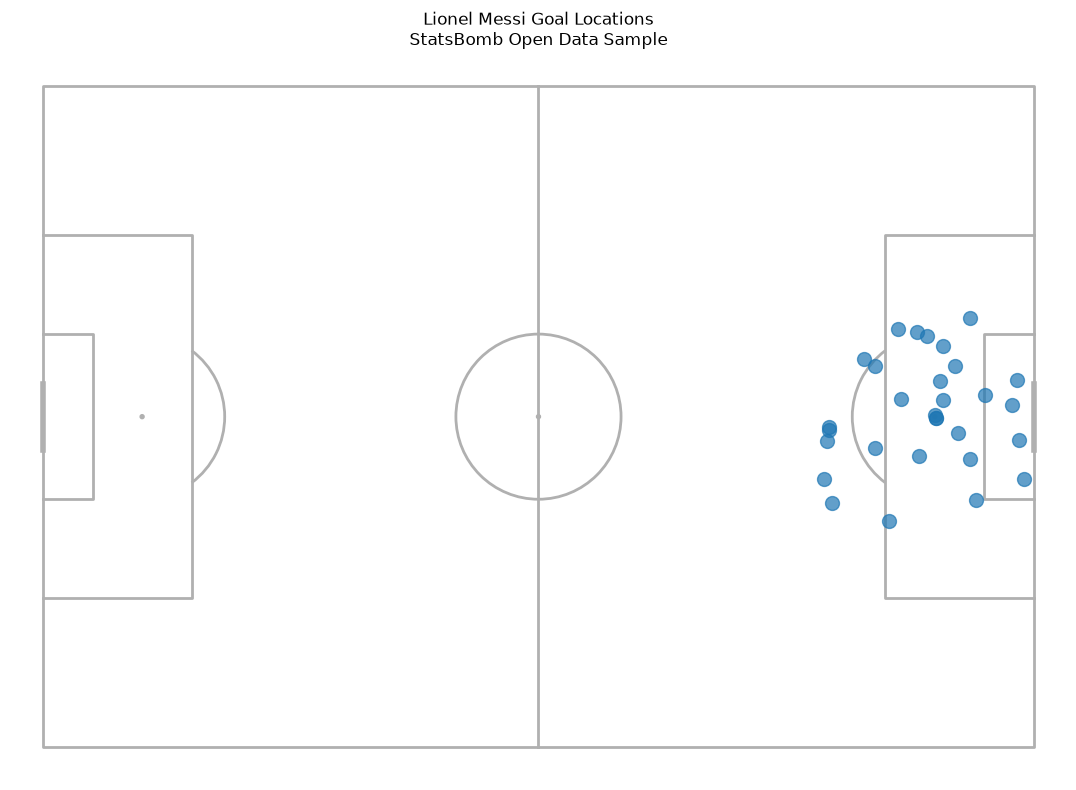

In [29]:
pitch = Pitch(
    pitch_type="statsbomb",
    pitch_length=120,
    pitch_width=80
)

fig, ax = pitch.draw(
    figsize=(12,8)
)

pitch.scatter(
    sb_goals["x"],
    sb_goals["y"],
    ax=ax,
    s=100,
    alpha=0.7
)

plt.title(
    "Lionel Messi Goal Locations\nStatsBomb Open Data Sample"
)

plt.show()

## Case Study 1 Conclusion

The first case study demonstrates that Messi's scoring style can be
understood through several connected dimensions.

We first examined his finishing method, followed by the relationship
between playing position and scoring method. We then examined when
his goals occur and which teammates most frequently assisted him.

Finally, StatsBomb spatial event data allowed us to move from
traditional statistical charts to a football-pitch representation of
his goals.

Together, these visualizations provide a multidimensional view of
how Lionel Messi creates and converts scoring opportunities.